<a href="https://colab.research.google.com/github/gibranfp/CursoAprendizajeProfundo/blob/2027-1/notebooks/5a_dcgan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Generación de imágenes mediante DCGAN
En esta libreta se programa y entrena una red generativa adversaria convolucional profunda (DCGAN) para la generación de imágenes de rostros.

In [1]:
import os
from math import sqrt, floor, ceil

import numpy as np
import matplotlib.pyplot as plt

import torch as th
from torch import nn
from torch.utils.data import DataLoader

from torch.utils.tensorboard import SummaryWriter

from datasets import load_dataset
import torchvision.transforms.v2 as T

SEED = 42
N_MUESTRAS_IMG = 32
FREQ_GENVIS = 2
N_EPOCAS = 10
N_TRAB = os.cpu_count() or 1
TBDIR = './runs/'
DC = th.device('cuda:0' if th.cuda.is_available() else 'cpu')

# valores de hiperparámetros sugeridos en artículo de DCGAN
T_IMAGEN = 64
N_CANALES = 1024
T_LOTE = 128
T_EMB = 100
LR = 0.0002
BETA1 = 0.5

# Por reproducibilidad
th.manual_seed(SEED)
np.random.seed(SEED)

## Conjunto de imágenes
Cargamos el conjunto de imágenes de rostros CelebA desde Hugging Face Hub.

In [2]:
ds = load_dataset("flwrlabs/celeba", split="train")

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/19 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/19 [00:00<?, ?it/s]

Definimos las transformaciones que redimensionan y recortan al centro las imágenes, las convierten a `Tensor` y escalan sus valores a un rango de $-1$ a $1$. Las transformaciones se aplican al vuelo con `set_transform` cada vez que se accede a un elemento del conjunto.

In [3]:
tr = T.Compose([T.ToImage(),
                T.Resize(T_IMAGEN, antialias=True),
                T.CenterCrop(T_IMAGEN),
                T.ToDtype(th.float32, scale=True),
                T.Normalize(mean=(0.5, 0.5, 0.5),
                            std=(0.5, 0.5, 0.5))])

def transforma(lote):
  return {'image': [tr(img.convert('RGB')) for img in lote['image']]}

ds.set_transform(transforma)

dl = DataLoader(ds,
                batch_size=T_LOTE,
                shuffle=True,
                drop_last=True,
                num_workers=N_TRAB)

lote = next(iter(dl))
print(f'Imágenes = {lote["image"].shape}')

Imágenes = torch.Size([128, 3, 64, 64])


Creamos una función para visualizar una rejilla de imágenes.

In [4]:
def muestra_imagenes(imgs: np.ndarray) -> None:
  t_muestra = imgs.shape[0]
  n_filas = floor(sqrt(t_muestra))
  n_cols = ceil(sqrt(t_muestra))

  fig, ax = plt.subplots(nrows=n_filas, ncols=n_cols)

  for i in range(n_filas):
    for j in range(n_cols):
      idx = i * n_cols + j
      ax[i, j].imshow(imgs[idx])
      ax[i, j].axis('off')

  fig.subplots_adjust(wspace=-0.5, hspace=0)
  plt.show()

Mostramos un lote del conjunto de datos.

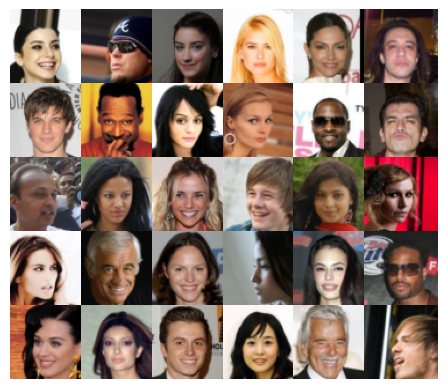

In [5]:
muestra_imagenes(lote["image"][:N_MUESTRAS_IMG].permute(0, 2, 3, 1).numpy() * 0.5 + 0.5)

## Arquitectura de DCGAN

### Generador

El vector de entrada ($z$) al generador se proyecta mediante una capa lineal, cuya salida se pasa por una capa de normalización por lotes y se redimensiona para formar un mapa de $4 \times 4 \times C$, donde $C$ es el número de canales inicial. Este mapa se procesa de forma secuencial por capas de convoluciones transpuestas seguidas por capas de normalización por lotes, excepto en la última capa de convolución transpuesta. Después de cada capa de normalización por lotes se aplica la función de activación ReLU, mientras que en la  última convolución transpuesta se aplica una función de activación tangente hiperbólica.

In [6]:
class Generador(nn.Module):
  def __init__(self,
               t_emb: int,
               nf = 1024) -> None:
    super().__init__()

    self.nf = nf
    self.t_emb = t_emb

    self.proj = nn.Linear(t_emb, 4 * 4 * nf, bias=False)

    self.bn_proj = nn.BatchNorm1d(4 * 4 * nf)

    self.bloque1 = nn.Sequential(nn.ConvTranspose2d(nf, nf // 2, 4, 2, 1, bias=False),
                                 nn.BatchNorm2d(nf // 2))
    self.bloque2 = nn.Sequential(nn.ConvTranspose2d(nf // 2, nf // 4, 4, 2, 1, bias=False),
                                 nn.BatchNorm2d(nf // 4))
    self.bloque3 = nn.Sequential(nn.ConvTranspose2d(nf // 4, nf // 8, 4, 2, 1, bias=False),
                                 nn.BatchNorm2d(nf // 8))
    self.output = nn.ConvTranspose2d(nf // 8, 3, 4, 2, 1, bias=False)

  def forward(self,
              x: th.Tensor) -> th.Tensor:
    x = self.proj(x)
    x = nn.functional.relu(self.bn_proj(x))
    x = x.reshape(-1, self.nf, 4, 4)

    x = nn.functional.relu(self.bloque1(x))
    x = nn.functional.relu(self.bloque2(x))
    x = nn.functional.relu(self.bloque3(x))
    x = nn.functional.tanh(self.output(x))

    return x

Definimos función para generar muestras con la red generadora.

In [7]:
def genera_imagenes(gen: nn.Module,
                    n_imagenes: int,
                    t_emb: int,
                    disp: th.device) -> np.ndarray:
  gen.eval()
  with th.no_grad():
    # Muestreamos vectores latentes
    Z = th.randn((n_imagenes, t_emb), device=disp)

    # Generamos imágenes a partir de vectores latentes muestreados
    X_gen = gen(Z)

    # Cambiamos posición de canales de las imágenes generadas, las pasamos
    # al CPU y normalizamos sus valores
    X_gen = X_gen.permute(0, 2, 3, 1).cpu().numpy() * 0.5 + 0.5

    return X_gen


### Discriminador
El discriminador tiene una arquitectura estándar de red convolucional, compuesta por capas convolucionales seguidas por capas de normalización por lotes (excepto la primera, como se sugiere en el artículo de DCGAN) y funciones de activación Leaky ReLU. El mapa de características resultante de las capas anteriores se convierte a un vector y se pasa por una sola neurona lineal. La función sigmoide no se aplica en la red sino dentro de la función de pérdida (`BCEWithLogitsLoss`), lo cual es numéricamente más estable.

In [8]:
class Discriminador(nn.Module):
  def __init__(self,
               nf: int = 1024) -> None:
    super().__init__()

    self.conv1 = nn.Conv2d(3, nf // 8, 4, 2, 1, bias=False)
    self.conv2 = nn.Conv2d(nf // 8, nf // 4, 4, 2, 1, bias=False)
    self.bn2 = nn.BatchNorm2d(nf // 4)
    self.conv3 = nn.Conv2d(nf // 4, nf // 2, 4, 2, 1, bias=False)
    self.bn3 = nn.BatchNorm2d(nf // 2)
    self.conv4 = nn.Conv2d(nf // 2, nf, 4, 2, 1, bias=False)
    self.bn4 = nn.BatchNorm2d(nf)

    self.output = nn.Linear(nf * 4 * 4, 1, bias=False)

  def forward(self,
              x: th.Tensor) -> th.Tensor:
    x = self.conv1(x)
    x = nn.functional.leaky_relu(x, negative_slope=0.2)

    x = self.conv2(x)
    x = self.bn2(x)
    x = nn.functional.leaky_relu(x, negative_slope=0.2)

    x = self.conv3(x)
    x = self.bn3(x)
    x = nn.functional.leaky_relu(x, negative_slope=0.2)

    x = self.conv4(x)
    x = self.bn4(x)
    x = nn.functional.leaky_relu(x, negative_slope=0.2)

    x = self.output(x.flatten(start_dim=1))
    return x

### Inicializador de pesos
En el artículo de DCGAN ([Radford et al. 2016](https://arxiv.org/abs/1511.06434)), se menciona que todos los pesos se inicializan a partir de una distribución Normal con media de 0 y desviación estándar de 0.02. Para llevar a cabo esto, definimos la siguiente función:

In [9]:
def weights_init(m: nn.Module) -> None:
  if isinstance(m, (nn.Conv2d,
                    nn.ConvTranspose2d,
                    nn.Linear)):
    nn.init.normal_(m.weight, 0.0, 0.02)
  elif isinstance(m, (nn.BatchNorm1d,
                      nn.BatchNorm2d)):
    nn.init.normal_(m.weight, 1.0, 0.02)
    nn.init.zeros_(m.bias)

## Función de pérdida
La función de pérdida empleada está dada por

$$
\begin{align*}
  \mathcal{L}_{{D}} = & - \mathbb{E}_{\mathbf{x}}\left[\log \{ {{D}_{\boldsymbol{\Theta}}}(\mathbf{x})\}\right] - \mathbb{E}_\mathbf{z} \left[\log \{1-{D}_{\boldsymbol{\Theta}}({G}_{\boldsymbol{\Phi}}(\mathbf{z}))\}\right]\\
  \mathcal{L}_{{G}} = & - \mathbb{E}_\mathbf{z} \left[\log\{{D}_{\boldsymbol{\Theta}}({G}_{\boldsymbol{\Phi}}(\mathbf{z}))\}\right]
\end{align*}
$$

donde $\boldsymbol{\Theta}$ y $\boldsymbol{\Phi}$ son los parámetros del discriminador y del generador, respectivamente.

La pérdida del generador corresponde a la versión no saturante propuesta en el artículo original de GAN, que da gradientes más fuertes al inicio del entrenamiento cuando el discriminador rechaza fácilmente las imágenes generadas. En la práctica, las esperanzas se aproximan con promedios sobre el lote y $D_{\boldsymbol{\Theta}}$ se calcula aplicando la sigmoide a la salida del discriminador dentro de `BCEWithLogitsLoss`.

In [10]:
class PerdidaGAN:
  def __init__(self) -> None:
    self.ecc = nn.BCEWithLogitsLoss()

  def gen(self,
          falsas: th.Tensor) -> th.Tensor:
    return self.ecc(falsas, th.ones_like(falsas))

  def dis(self,
          reales: th.Tensor,
          falsas: th.Tensor) -> th.Tensor:
    perdida_real = self.ecc(reales, th.ones_like(reales))
    perdida_falsa = self.ecc(falsas, th.zeros_like(falsas))
    return perdida_real + perdida_falsa

## Funciones para el entrenamiento
Para facilitar el entrenamiento, definimos diversas funciones

### Registrar información para Tensorboard
Para guardar información que pueda visualizarse con Tensorboard, instanciamos la clase `SummaryWriter` del submódulo `tensorboard` del módulo `utils` y escribimos información mediante los distintos métodos disponibles (por ej. `add_scalar`, `add_image`, `add_histogram`, etc.).

In [11]:
def registra_info_tboard(writer: SummaryWriter,
                         epoca: int,
                         hist: dict[str, np.ndarray]) -> None:
  for (m,v) in hist.items():
    writer.add_scalar(m, v[epoca], epoca)

### Paso de entrenamiento
Definimos una función que realiza un paso de entrenamiento, a la cual llamaremos `paso_ent`. Esta función recibe como argumentos:
- El generador como una instancia de `Module` (`gen`).
- El discriminador como una instancia de `Module` (`dis`).
- La función de pérdida como instancia de `PerdidaGAN` (`fp`).
- Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos del generador (`opt_gen`).
- Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos del discriminador (`opt_dis`).
- Una instancia de `Tensor` con el lote de entradas (`X`).

Para cada paso de entrenamiento, se realiza lo siguiente:

1. Se muestrea un lote de vectores latentes y se genera un lote de imágenes.
2. Se pasa por el discriminador el lote de imágenes reales.
3. Se pasa por el discriminador el lote de imágenes generadas desconectadas del grafo de cómputo, ya que en este punto no se van a obtener los gradientes respecto al generador.
4. Se calcula la pérdida del discriminador, se obtienen sus gradientes y se actualizan los parámetros del discriminador.
5. Se pasa por el discriminador (ya actualizado) el lote de imágenes generadas conectadas al grafo de cómputo.
6. Se calcula la pérdida del generador, se obtienen sus gradientes y se actualizan los parámetros del generador.

Nota que el discriminador se actualiza antes de calcular la pérdida del generador. Si ambas retropropagaciones se hicieran antes de actualizar, los gradientes de la pérdida del generador también se acumularían en los parámetros del discriminador y este se actualizaría en una dirección incorrecta.

In [12]:
def paso_ent(gen: nn.Module,
             dis: nn.Module,
             fp: PerdidaGAN,
             opt_gen: th.optim.Optimizer,
             opt_dis: th.optim.Optimizer,
             X: th.Tensor) -> tuple[float, float]:
    # Muestreamos vectores latentes
    Z = th.randn((X.shape[0], T_EMB), device=X.device)

    # Generamos imágenes con vectores latentes
    X_gen = gen(Z)

    #
    # Actualización del discriminador
    #
    opt_dis.zero_grad()

    # Obtenemos salidas del discriminador para el lote de imágenes reales
    reales = dis(X).view(-1)

    # Desconectamos imágenes generadas de grafo de cómputo para evitar que
    # se intenten calcular gradientes de generador al calcular los gradientes
    # del discriminador
    X_gen_detached = X_gen.detach()

    # Obtenemos salidas del discriminador para el lote de imágenes generadas
    # desconectadas del grafo de cómputo para evitar que se calculen
    # gradientes del generador
    falsas_detached = dis(X_gen_detached).view(-1)

    # Calculamos la pérdida del discriminador, sus gradientes y actualizamos
    perdida_dis = fp.dis(reales, falsas_detached)
    perdida_dis.backward()
    opt_dis.step()

    #
    # Actualización del generador
    #
    opt_gen.zero_grad()

    # Obtenemos salidas del discriminador para imágenes generadas conectadas
    # al grafo de cómputo para calcular los gradientes de la pérdida respecto
    # a los parámetros del generador
    falsas = dis(X_gen).view(-1)

    # Calculamos la pérdida del generador, sus gradientes y actualizamos
    perdida_gen = fp.gen(falsas)
    perdida_gen.backward()
    opt_gen.step()

    return perdida_gen.item(), perdida_dis.item()

### Función para el ciclo principal de entrenamiento
También definimos el ciclo de entrenamiento principal, que llamaremos `entrena`. Esta función recibe como argumentos:
- El generador como una instancia de `Module` (`gen`).
- El discriminador como una instancia de `Module` (`dis`).
- La función de pérdida como instancia de `PerdidaGAN` (`fp`).
- Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos del generador (`opt_gen`).
- Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos del discriminador (`opt_dis`).
- El cargador de datos del subconjunto de entrenamiento (`dl`).
- El número de épocas de entrenamiento (`n_epocas`).
- El dispositivo en el que se ejecutará el modelo (`disp`).
- Cada cuántas épocas generar y guardar imágenes de ejemplo con el modelo (`freq_vis`)
- La ruta al directorio donde se guardará la información para Tensorboard (`tbdir`).

Para cada una de las épocas, va tomando un lote de imágenes a la vez, con los cuales se realiza un paso de entrenamiento.

In [13]:
def entrena(gen: nn.Module,
            dis: nn.Module,
            fp: PerdidaGAN,
            opt_gen: th.optim.Optimizer,
            opt_dis: th.optim.Optimizer,
            dl: th.utils.data.DataLoader,
            n_epocas: int,
            disp: th.device,
            freq_vis: int = 5,
            tbdir: str = 'runs/') -> tuple[nn.Module, nn.Module, dict, list]:

  hist = {
          'perdida_gen': np.zeros(n_epocas),
          'perdida_dis': np.zeros(n_epocas)

  }

  tbwriter = SummaryWriter(tbdir)

  lst_img_gen = []
  for e in range(n_epocas):
    gen.train()
    dis.train()
    for lote in dl:
      X = lote["image"].to(disp)
      perdida_paso_gen, perdida_paso_dis = paso_ent(gen,
                                                    dis,
                                                    fp,
                                                    opt_gen,
                                                    opt_dis,
                                                    X)
      hist['perdida_gen'][e] += perdida_paso_gen
      hist['perdida_dis'][e] += perdida_paso_dis

    # Promediamos las pérdidas de la época
    hist['perdida_gen'][e] /= len(dl)
    hist['perdida_dis'][e] /= len(dl)

    registra_info_tboard(tbwriter, e, hist)

    print(f'Época {e + 1}/{n_epocas}: '
          f'Pérdida G = {hist["perdida_gen"][e]:.3f}, '
          f'Pérdida D = {hist["perdida_dis"][e]:.3f}')

    # Guarda imágenes generadas con el modelo cada cierto número de épocas
    if e % freq_vis == 0 or e == n_epocas - 1:
      X_gen = genera_imagenes(gen, N_MUESTRAS_IMG, T_EMB, disp)
      lst_img_gen.append((e + 1, X_gen))

  return gen, dis, hist, lst_img_gen

## Entrenamiento
Se instancia un optimizador para el generador, otro más para el discriminador y la función de pérdida y se entrena la GAN.

In [14]:
gen = Generador(T_EMB, N_CANALES).apply(weights_init)
dis = Discriminador(N_CANALES).apply(weights_init)


opt_gen = th.optim.Adam(gen.parameters(),
                        lr = LR, betas = (BETA1, 0.999))
opt_dis = th.optim.Adam(dis.parameters(),
                        lr = LR, betas = (BETA1, 0.999))

fp = PerdidaGAN()

gen.to(DC)
dis.to(DC)
gen, dis, hist, lst_img_gen = entrena(gen,
                                      dis,
                                      fp,
                                      opt_gen,
                                      opt_dis,
                                      dl,
                                      N_EPOCAS,
                                      DC,
                                      FREQ_GENVIS,
                                      tbdir=TBDIR)


Época 1/10: Pérdida G = 6.601, Pérdida D = 0.932
Época 2/10: Pérdida G = 3.354, Pérdida D = 0.831
Época 3/10: Pérdida G = 2.950, Pérdida D = 0.852
Época 4/10: Pérdida G = 2.821, Pérdida D = 0.878
Época 5/10: Pérdida G = 2.807, Pérdida D = 0.869
Época 6/10: Pérdida G = 2.821, Pérdida D = 0.802
Época 7/10: Pérdida G = 2.932, Pérdida D = 0.774
Época 8/10: Pérdida G = 3.002, Pérdida D = 0.743
Época 9/10: Pérdida G = 3.179, Pérdida D = 0.663
Época 10/10: Pérdida G = 3.277, Pérdida D = 0.657


Se grafican la pérdida del generador y del discriminador.

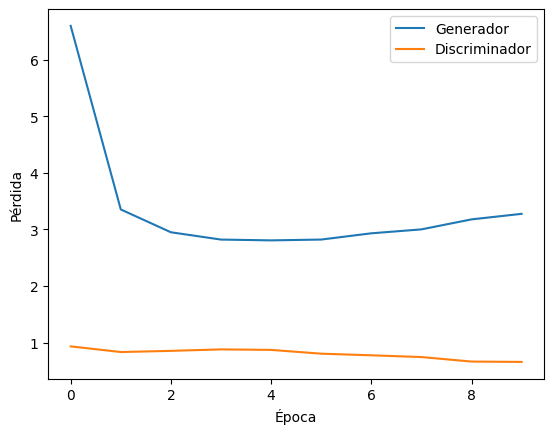

In [15]:
plt.plot(hist['perdida_gen'], label = 'Generador')
plt.plot(hist['perdida_dis'], label = 'Discriminador')
plt.xlabel('Época')
plt.ylabel('Pérdida')
plt.legend()
plt.show()

Visualizamos los lotes de imágenes generadas guardadas.

Época 1


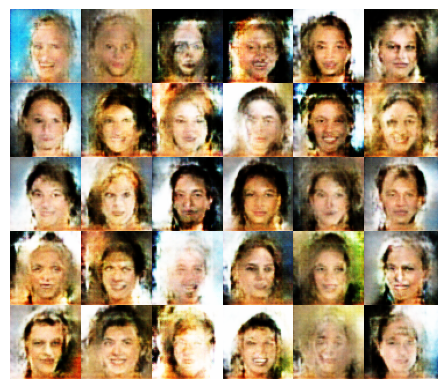

Época 3


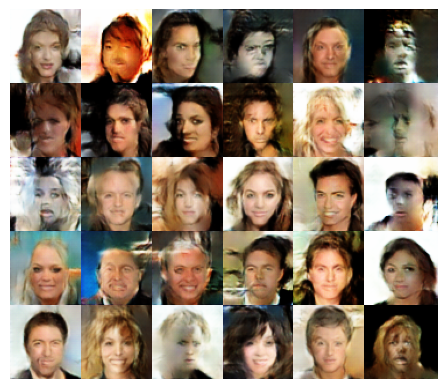

Época 5


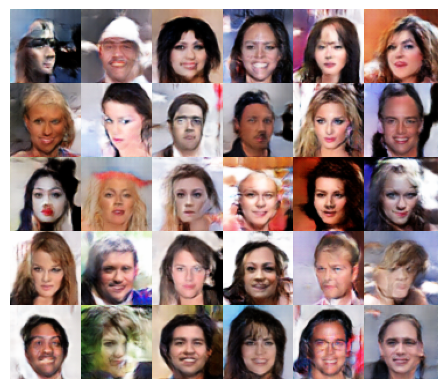

Época 7


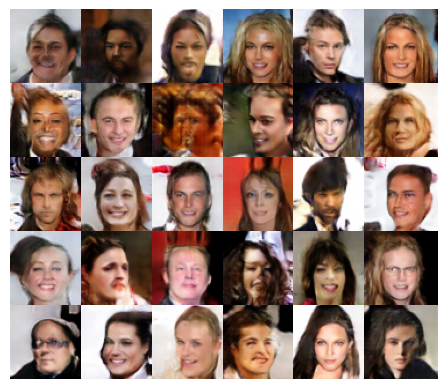

Época 9


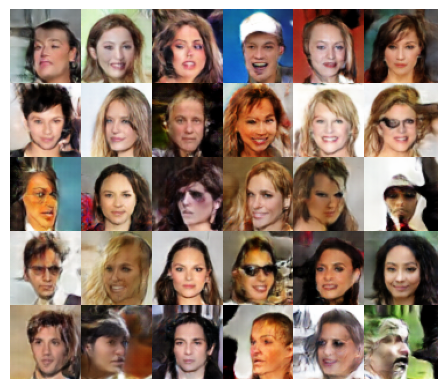

Época 10


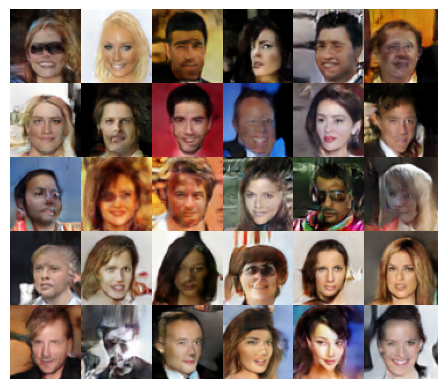

In [16]:
for e, imgs in lst_img_gen:
  print(f'Época {e}')
  muestra_imagenes(imgs)